In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
salary = pd.read_csv('Salary_Data.csv').values

- **Salary 값으로 경력(YearsExperience) 예측**하는 **polynomial regression model** 생성
- **X**: 두번째 열(마지막 열)
- **y**: 첫번째 열

In [3]:
# X는 반드시 2d 여야 함 (행과 열을 모두 범위로 지정해야 함)
X = salary[:,-1:] # -1: -> 마지막 열부터 끝까지를 의미하므로, 마지막 열만 포함됨
y = salary[:,0]

In [4]:
from sklearn.model_selection import train_test_split
X_train,X_test,y_train,y_test = train_test_split(X,y,test_size=0.2,random_state=42)

## polynomial feature 생성(확장)

In [5]:
from sklearn.preprocessing import PolynomialFeatures
poly1 = PolynomialFeatures(degree=2)
poly1.fit(X_train)
# fit: 입력된 형태의 X를 어떻게 변환할지 결정, (변환식 계산)
Xpoly_train1 = poly1.transform(X_train)
# PolynomialFeatures 변환 결과의 첫번째 열은 1임
# ex> degree가 2일 경우 [1, x, x*x]
# ex> degree가 3일 경우 [1, x, x*x, x*x*x]

poly2 = PolynomialFeatures(degree=5)
poly2.fit(X_train)
Xpoly_train2 = poly2.transform(X_train)

## Linear regression 학습

- Polynomial regression은 X를 **polynomial feature로 확장하는 점을 제외하고는 Linear regression과 동일**함

In [6]:
from sklearn.linear_model import LinearRegression
poly_lr1 = LinearRegression()
poly_lr1.fit(Xpoly_train1,y_train)
poly_lr2 = LinearRegression()
poly_lr2.fit(Xpoly_train2,y_train)
lr = LinearRegression()
lr.fit(X_train,y_train)

LinearRegression()

## 결과 시각화

- 임의의 입력 X에 대한 예측값을 구해, model을 시각화한다.

In [7]:
# regression model의 입력(salary) 범위를 35000~130000으로 함
# np.arange(start,end,step): start부터 end까지 step 간격으로 생성(end는 포함하지 않음), 1d
# np.linspace(start,end,num): start부터 end까지 동일한 간격의 num개의 값 생성(end 포함), 1d
# 최소값 35000부터 최대값 130000까지 동일한 간격으로 200개의 x를 생성함
X_in = np.linspace(35000,130000,200)

In [8]:
# X_in sample에 대한 regression model의 예측값
# X_in은 반드시 2d여야 함
# ndarray.reshape(a,b): ndarray를 a,b shape으로 변경함
#                       a 또는 b 대신 -1을 사용할 경우, 데이터 수에 맞춰 자동 계산
X_in_2d = X_in.reshape(-1,1)
# X_in.reshape(-1,1): X_in을 1개의 열을 가진 2d array로 변환함
# ndarray가 1d일 경우, ndarray.reshape(-1,1)은 ndarray를 2d array로 변환함
# 위의 경우, X_in은 (200,)이므로 X_in.reshape(200,1)과 동일함

In [9]:
# 입력 X_in을 학습된 training data와 동일한 degree로 변환함
X_in_poly1 = poly1.transform(X_in_2d)
y_pred_poly1 = poly_lr1.predict(X_in_poly1)
X_in_poly2 = poly2.transform(X_in_2d)
y_pred_poly2 = poly_lr2.predict(X_in_poly2)
y_pred_lr = lr.predict(X_in_2d)

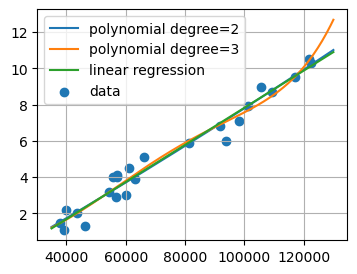

In [10]:
plt.figure(figsize=(4,3))
plt.plot(X_in_2d,y_pred_poly1,label='polynomial degree=2')
plt.plot(X_in_2d,y_pred_poly2,label='polynomial degree=3')
plt.plot(X_in_2d,y_pred_lr,label='linear regression')
plt.scatter(X_train,y_train,label='data')
plt.legend()
plt.grid()

In [19]:
X_poly1 = poly1.transform(X_test)
y_poly1 = poly_lr1.predict(X_poly1)
X_poly2 = poly2.transform(X_test)
y_poly2 = poly_lr2.predict(X_poly2)
y_lr = lr.predict(X_test)

In [20]:
from sklearn.metrics import mean_squared_error
print('linear regression MSE  : ',mean_squared_error(y_test,y_lr))
print('polynomial degree=2 MSE: ',mean_squared_error(y_test,y_poly1))
print('polynomial degree=5 MSE: ',mean_squared_error(y_test,y_poly2))

linear regression MSE  :  0.5191320118982418
polynomial degree=2 MSE:  0.5063579578667955
polynomial degree=5 MSE:  0.5488435247697995
